# Übung zu kMeans

In der Vorlesung wurde das Cluster-Verfahren kMeans besprochen. Dieses und zusätzliche Erweiterungen werden wir in dieser Übung implementieren.

In [7]:
import matplotlib.pyplot as plt
import numpy as np

Mit folgendem Code erzeugen wir ein Beispielcorpus mit 300 Beispielen und einer Merkmaledimension von zwei. Das Corpus kann in 4 Cluster eingeteilt werden.
Wir verwenden dieses zum Evaluieren unserer k-Means-Implementierung.

(300, 2)


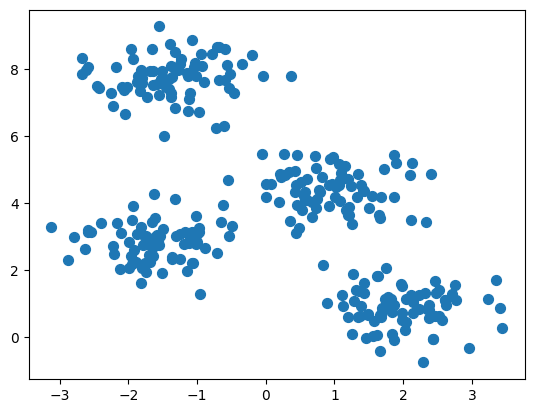

In [8]:
from sklearn.datasets import make_blobs

X, y_true = make_blobs(n_samples=300, centers=4,
                       cluster_std=0.60, random_state=0)
print(X.shape)
plt.scatter(X[:, 0], X[:, 1], s=50);

## Implementieren Sie den k-Means Algorithmus

In [9]:
"""
ignored inputs: 
init (how to select centroids) 
tol (relative tolerance with regards to Frobenius norm)
verbose
algorithm (llyod or elkan) 
copy_x: bool, (copy data or modify original data)
"""

import random
import sys

class MyKMeans:
    def __init__(self, n_clusters, n_init=4, max_iter=100, random_state=1899):
        self.n_clusters = n_clusters
        # Number of times the k-means algorithm is run with different centroid seeds
        self.n_init = n_init
        self.max_iter = max_iter
        self.random_state = random_state
        random.seed(self.random_state)

        self.centroids = None
        self.backing_centroids = None
                
        self.count_vecs = None
        self.agg_vecs = None
        
        # each corresponding to an index into self.centroids
        # i.e. forall e of self.labels: e < self.n_clusters
        self.labels = None

        # Sum of squared distances of samples to their assigned centroid
        self.inertia = 0
        
    """
    kmeans++ scheme for initial centroids
    """
    def init_centroids(self, data):
        h = random.randint(0, len(data) - 1)
        centroids = np.zeros((self.n_clusters, data.shape[1]))
        centroids[0] = data[h] 
        
        """
        https://en.wikipedia.org/wiki/Inverse_transform_sampling
        
        General intuition:
        If persons A, B, and C own all the property in city N,
        and person A owns half of the total,
        then, falling from the sky,
        I am more likely to hit one of A's properties.

        In the following, 
        we split the interval [0, sum_sq_distances[ in N slices.
        Points further away correspond to larger slices,
        (specifically, they are favored quadratically).
        Now picking a random number in the range [0, sum_sq_distances[,
        we are more likely to hit these larger slices.

        Using this we favour points that are spread apart 
        (unlikely to belong to the same cluster)
        as centroids, but the process is still somewhat random.
        """
        len_centroids = 1
        distances_sq = np.zeros(data.shape[0]) 
        
        while len_centroids < self.n_clusters:
            for j in range(0, len(data)):
                point = data[j] 
                min_dist = np.linalg.norm(centroids[0] - point, axis=0)
                for m in range(1, len(centroids)):
                    d = np.linalg.norm(centroids[m] - point, axis=0)
                    if d < min_dist: min_dist = d
                
                distances_sq[j] = min_dist ** 2
            
            total = np.sum(distances_sq)
            
            # assert total > 0
            
            threshold = random.uniform(0, total)
            
            agg = 0
            for i in range(0, len(data)):
                agg += distances_sq[i] 
                if agg >= threshold:
                    centroids[len_centroids] = data[i] 
                    len_centroids += 1 
                    break

        self.centroids = centroids

    """
    kmeans():
    Wähle randomisiert k Trainingsbeispiele als initiale Centroids
    While true:
        . ordne jedes Beispiel dem Cluster zu, mit dem geringsten Abstand zum Centroid (Expectation)
        . berechne k neue Centroids durch Mitteln der Datenpunkte pro Cluster (Maximisation)
    """
    def kmeans(self, data) -> int:
        """
        Returns the number of times the main loop ran before the centroids converged.
        If the centroids do not converge after a maximum number of iterations,
        sys.maxsize is returned. Use the return value to test for this condition.
        """
        MUST_CONVERGE = 100
        
        assert len(data.shape) > 0 
        assert data.shape[1] > 0 
        self.init_centroids(data)
        
               
        for attempt in range(MUST_CONVERGE):
            self.inertia = 0
            
            self.agg_vecs.fill(0)
            self.count_vecs.fill(0)
            
            # Expectation
            for i in range(data.shape[0]):
                vec = data[i]
                
                min_dist = np.linalg.norm(vec - self.centroids[0], axis=0) 
                best_label = 0 
                
                for u in range(1, self.n_clusters):
                    d = np.linalg.norm(vec - self.centroids[u], axis=0)
                    if d < min_dist:
                        min_dist = d
                        best_label = u

                self.inertia += min_dist ** 2
                
                self.labels[i] = best_label

                self.agg_vecs[best_label] += vec
                self.count_vecs[best_label] += 1

            # Maximisation
            for u in range(self.n_clusters):
                 self.backing_centroids[u] = self.agg_vecs[u] / self.count_vecs[u]

            if np.array_equal(self.backing_centroids, self.centroids):
                return (attempt + 1) 
            else:
                temp = self.centroids 
                self.centroids = self.backing_centroids 
                self.backing_centroids = temp

        return sys.maxsize 
                
    """
    best = kMeans(dataset)
    for t in range(numTrials):
        C = kMeans(dataset)
        if dissimilarity(C) < dissimilarity(Best):
            best = C
    return best
    """
    def fit(self, data):
        self.labels = np.zeros(len(data))
        self.copy_labels = np.zeros(len(data))
        self.agg_vecs = np.zeros((self.n_clusters, data.shape[1]))
        self.count_vecs = np.zeros((self.n_clusters,)) 
        self.backing_centroids = np.zeros((self.n_clusters, data.shape[1]))
        self.copy_centroids = np.zeros((self.n_clusters, data.shape[1]))
        
        self.kmeans(data)
        
        sum_squares = self.inertia
        
        for _ in range(1, self.n_init):
            np.copyto(self.copy_centroids, self.centroids)
            np.copyto(self.copy_labels, self.labels)
            self.kmeans(data)
            
            if self.inertia < sum_squares:
                sum_squares = self.inertia 
            else:
                # just swap references to undo
                temp_1 = self.centroids
                self.centroids = self.copy_centroids
                self.copy_centroids = temp_1

                temp_2 = self.labels
                self.labels = self.copy_labels 
                self.copy_labels = temp_2
        
    """
    . determine closest centroid to each vector
    . assign label to vec accordingly
    """
    def predict(self, new_data) -> np.ndarray:
        new_labels = np.zeros(new_data.shape[0])
        
        for i in range(new_data.shape[0]):
                vec = new_data[i]
                
                min_dist = np.linalg.norm(vec - self.centroids[0], axis=0) 
                best_label = 0 
                
                for u in range(1, self.n_clusters):
                    d = np.linalg.norm(vec - self.centroids[u], axis=0)
                    if d < min_dist:
                        min_dist = d
                        best_label = u
                
                new_labels[i] = best_label

        return new_labels

    def fit_predict(self, data) -> np.ndarray:
        self.fit(data)
        return self.labels

## Plotten sie die gefunden Cluster mit den zugehörigen Zentroiden

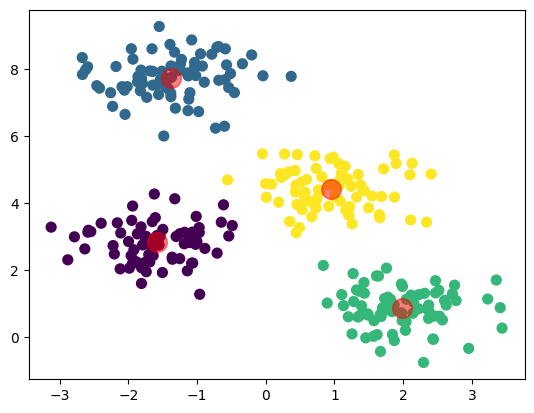

In [10]:
yousef_kmeans = MyKMeans(n_clusters=4)
yousef_kmeans.fit(X)
y_kmeans = yousef_kmeans.labels


plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis')

centers = yousef_kmeans.centroids
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)

## In der Vorlesung haben wir ein Verfahren besprochen, mit dem das Problem der initialen Centroide gelöst werden kann. Implementieren sie dieses und Testen ihre k-Means-Erweiterung.

In [11]:
# see fit()

## Testen Sie ihr Verfahren mit einem Datensatz ihrer Wahl und analysieren Sie die Ergebnisse

In [12]:
from sklearn.datasets import load_digits
digits = load_digits()
print(digits.data.shape)

(1797, 64)


(10, 64)


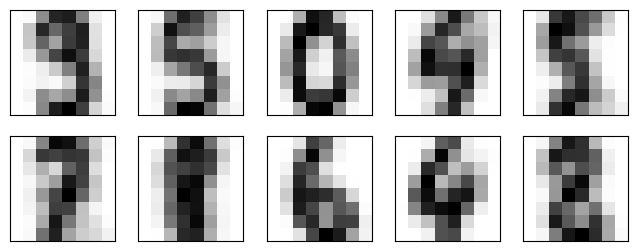

In [13]:
n_cluster = 10 
d_kmeans = MyKMeans(n_clusters=10)
clusters = d_kmeans.fit_predict(digits.data)

y=(int)(n_cluster/2)

fig, ax = plt.subplots(2, y, figsize=(8, 3))
print(d_kmeans.centroids.shape)

centers_reshaped = d_kmeans.centroids.copy().reshape(n_cluster, 8, 8)
for axi, center in zip(ax.flat, centers_reshaped):
    axi.set(xticks=[], yticks=[])
    axi.imshow(center, interpolation='nearest', cmap=plt.cm.binary)